# Цель: проверить, значима ли разница между gate_30 и gate_40. И если да — в какую сторону и насколько.

Z-test для пропорций (retention_1, retention_7), Mann-Whitney U для sum_gamerounds (не t-test — из-за скошенности), доверительные интервалы, effect size.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

# Загружаем данные из CSV
df = pd.read_csv('../data/raw_data/cookie_cats.csv')
print("Загружено:", len(df))

# Разделяем на группы
gate_30 = df[df['version'] == 'gate_30']
gate_40 = df[df['version'] == 'gate_40']

print(f"gate_30: {len(gate_30):,}")
print(f"gate_40: {len(gate_40):,}")

Загружено: 90189
gate_30: 44,700
gate_40: 45,489


# Z-test для retention_1

In [3]:
# Данные для теста
successes = np.array([
    gate_30['retention_1'].sum(),
    gate_40['retention_1'].sum()
])
nobs = np.array([len(gate_30), len(gate_40)])

# Конверсии
conv_30 = successes[0] / nobs[0]
conv_40 = successes[1] / nobs[1]

print("=== RETENTION 1 ===")
print(f"gate_30: {conv_30:.4%} ({successes[0]:,} из {nobs[0]:,})")
print(f"gate_40: {conv_40:.4%} ({successes[1]:,} из {nobs[1]:,})")
print(f"Разница: {conv_40 - conv_30:+.4%}")
print()

# Z-test
z_stat, p_value = proportions_ztest(successes, nobs, alternative='two-sided')

print(f"Z-statistic: {z_stat:.4f}")
print(f"p-value: {p_value:.4f}")
print()

if p_value < 0.05:
    print("✅ Разница статистически значима (p < 0.05)")
else:
    print("❌ Разница НЕ значима (p >= 0.05)")

=== RETENTION 1 ===
gate_30: 44.8188% (20,034 из 44,700)
gate_40: 44.2283% (20,119 из 45,489)
Разница: -0.5905%

Z-statistic: 1.7841
p-value: 0.0744

❌ Разница НЕ значима (p >= 0.05)


# Доверительный интервал для retention_1

In [4]:
# 95% доверительные интервалы для каждой группы
ci_30 = proportion_confint(successes[0], nobs[0], alpha=0.05, method='wilson')
ci_40 = proportion_confint(successes[1], nobs[1], alpha=0.05, method='wilson')

print("=== 95% ДИ для retention_1 ===")
print(f"gate_30: [{ci_30[0]:.4%}, {ci_30[1]:.4%}]")
print(f"gate_40: [{ci_40[0]:.4%}, {ci_40[1]:.4%}]")
print()

# Пересекаются ли интервалы?
if ci_30[0] <= ci_40[1] and ci_40[0] <= ci_30[1]:
    print("Интервалы пересекаются → разница может быть незначимой")
else:
    print("Интервалы НЕ пересекаются → разница значима")

=== 95% ДИ для retention_1 ===
gate_30: [44.3582%, 45.2802%]
gate_40: [43.7724%, 44.6851%]

Интервалы пересекаются → разница может быть незначимой


# Z-test для retention_7

In [5]:
successes_7 = np.array([
    gate_30['retention_7'].sum(),
    gate_40['retention_7'].sum()
])

conv_30_7 = successes_7[0] / nobs[0]
conv_40_7 = successes_7[1] / nobs[1]

print("=== RETENTION 7 ===")
print(f"gate_30: {conv_30_7:.4%} ({successes_7[0]:,} из {nobs[0]:,})")
print(f"gate_40: {conv_40_7:.4%} ({successes_7[1]:,} из {nobs[1]:,})")
print(f"Разница: {conv_40_7 - conv_30_7:+.4%}")
print()

z_stat_7, p_value_7 = proportions_ztest(successes_7, nobs, alternative='two-sided')

print(f"Z-statistic: {z_stat_7:.4f}")
print(f"p-value: {p_value_7:.4f}")
print()

if p_value_7 < 0.05:
    print("✅ Разница статистически значима (p < 0.05)")
else:
    print("❌ Разница НЕ значима (p >= 0.05)")

=== RETENTION 7 ===
gate_30: 19.0201% (8,502 из 44,700)
gate_40: 18.2000% (8,279 из 45,489)
Разница: -0.8201%

Z-statistic: 3.1644
p-value: 0.0016

✅ Разница статистически значима (p < 0.05)


# Доверительный интервал для retention_7

In [6]:
ci_30_7 = proportion_confint(successes_7[0], nobs[0], alpha=0.05, method='wilson')
ci_40_7 = proportion_confint(successes_7[1], nobs[1], alpha=0.05, method='wilson')

print("=== 95% ДИ для retention_7 ===")
print(f"gate_30: [{ci_30_7[0]:.4%}, {ci_30_7[1]:.4%}]")
print(f"gate_40: [{ci_40_7[0]:.4%}, {ci_40_7[1]:.4%}]")
print()

if ci_30_7[0] <= ci_40_7[1] and ci_40_7[0] <= ci_30_7[1]:
    print("Интервалы пересекаются")
else:
    print("Интервалы НЕ пересекаются → разница значима")

=== 95% ДИ для retention_7 ===
gate_30: [18.6590%, 19.3866%]
gate_40: [17.8481%, 18.5573%]

Интервалы НЕ пересекаются → разница значима


# Effect size (Cohen's h)

In [7]:
from statsmodels.stats.proportion import proportion_effectsize

# Cohen's h для ret1 и ret7
h_ret1 = proportion_effectsize(conv_30, conv_40)
h_ret7 = proportion_effectsize(conv_30_7, conv_40_7)

print("=== EFFECT SIZE (Cohen's h) ===")
print(f"retention_1: {h_ret1:.4f}")
print(f"retention_7: {h_ret7:.4f}")
print()

# Интерпретация
def interpret_h(h):
    h = abs(h)
    if h < 0.2:
        return "очень маленький"
    elif h < 0.5:
        return "маленький"
    elif h < 0.8:
        return "средний"
    else:
        return "большой"

print(f"retention_1: {interpret_h(h_ret1)} эффект")
print(f"retention_7: {interpret_h(h_ret7)} эффект")

=== EFFECT SIZE (Cohen's h) ===
retention_1: 0.0119
retention_7: 0.0211

retention_1: очень маленький эффект
retention_7: очень маленький эффект


# Mann-Whitney U для sum_gamerounds

In [8]:
# Mann-Whitney U
u_stat, p_value_mw = stats.mannwhitneyu(
    gate_30['sum_gamerounds'],
    gate_40['sum_gamerounds'],
    alternative='two-sided'
)

print("=== MANN-WHITNEY U (sum_gamerounds) ===")
print(f"U-statistic: {u_stat:,.0f}")
print(f"p-value: {p_value_mw:.4f}")
print()

print(f"Медиана gate_30: {gate_30['sum_gamerounds'].median():.0f}")
print(f"Медиана gate_40: {gate_40['sum_gamerounds'].median():.0f}")
print()

if p_value_mw < 0.05:
    print("✅ Разница статистически значима (p < 0.05)")
else:
    print("❌ Разница НЕ значима (p >= 0.05)")

=== MANN-WHITNEY U (sum_gamerounds) ===
U-statistic: 1,024,331,250
p-value: 0.0502

Медиана gate_30: 17
Медиана gate_40: 16

❌ Разница НЕ значима (p >= 0.05)


# Проверка устойчивости: без выбросов

In [9]:
# Убираем выбросы (> 99-й перцентиль)
threshold = df['sum_gamerounds'].quantile(0.99)
print(f"99-й перцентиль: {threshold:.0f}")
print()

df_clean = df[df['sum_gamerounds'] <= threshold]
gate_30_clean = df_clean[df_clean['version'] == 'gate_30']
gate_40_clean = df_clean[df_clean['version'] == 'gate_40']

print(f"После удаления выбросов: {len(df_clean):,} строк")
print()

# Mann-Whitney U без выбросов
u_stat_clean, p_value_clean = stats.mannwhitneyu(
    gate_30_clean['sum_gamerounds'],
    gate_40_clean['sum_gamerounds'],
    alternative='two-sided'
)

print("=== MANN-WHITNEY U (без выбросов) ===")
print(f"U-statistic: {u_stat_clean:,.0f}")
print(f"p-value: {p_value_clean:.4f}")
print()

print(f"Медиана gate_30: {gate_30_clean['sum_gamerounds'].median():.0f}")
print(f"Медиана gate_40: {gate_40_clean['sum_gamerounds'].median():.0f}")

99-й перцентиль: 493

После удаления выбросов: 89,291 строк

=== MANN-WHITNEY U (без выбросов) ===
U-statistic: 1,004,149,324
p-value: 0.0479

Медиана gate_30: 16
Медиана gate_40: 16


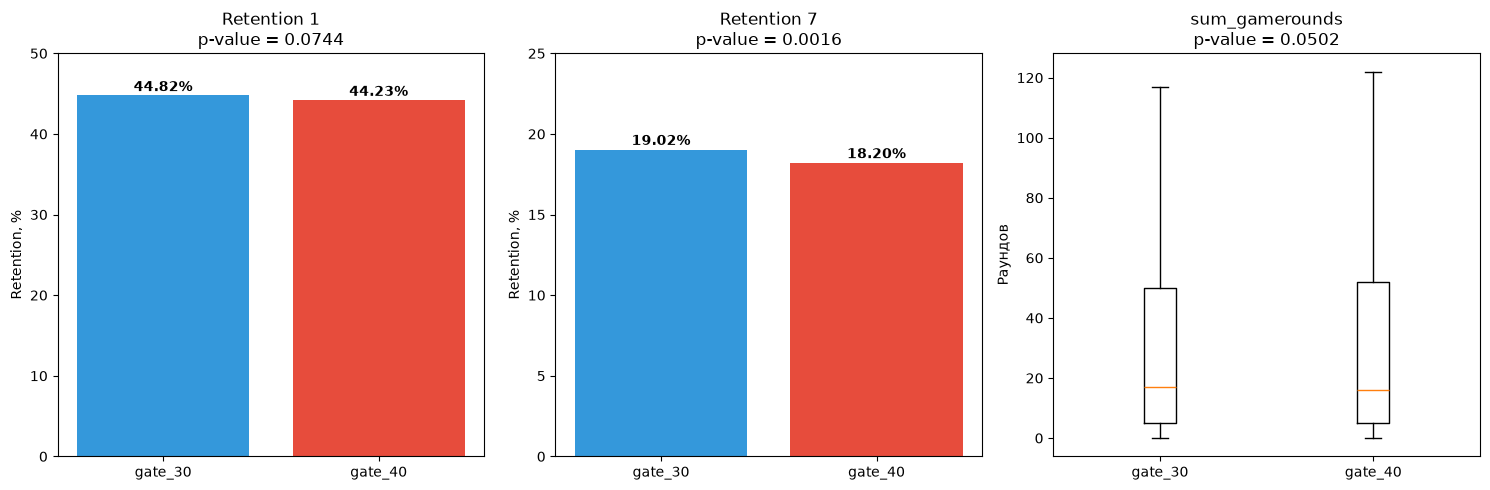

Сохранено: 05_statistical_tests.png


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Retention 1
ret1_data = [conv_30 * 100, conv_40 * 100]
bars = axes[0].bar(['gate_30', 'gate_40'], ret1_data, color=['#3498db', '#e74c3c'])
axes[0].set_title(f'Retention 1\np-value = {p_value:.4f}')
axes[0].set_ylabel('Retention, %')
axes[0].set_ylim(0, 50)
for bar, val in zip(bars, ret1_data):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 0.5, f'{val:.2f}%', 
                 ha='center', fontweight='bold')

# Retention 7
ret7_data = [conv_30_7 * 100, conv_40_7 * 100]
bars = axes[1].bar(['gate_30', 'gate_40'], ret7_data, color=['#3498db', '#e74c3c'])
axes[1].set_title(f'Retention 7\np-value = {p_value_7:.4f}')
axes[1].set_ylabel('Retention, %')
axes[1].set_ylim(0, 25)
for bar, val in zip(bars, ret7_data):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.3, f'{val:.2f}%', 
                 ha='center', fontweight='bold')

# Распределение sum_gamerounds
axes[2].boxplot(
    [gate_30['sum_gamerounds'], gate_40['sum_gamerounds']],
    tick_labels=['gate_30', 'gate_40'],
    showfliers=False
)
axes[2].set_title(f'sum_gamerounds\np-value = {p_value_mw:.4f}')
axes[2].set_ylabel('Раундов')

plt.tight_layout()
plt.savefig('../data/processed_data/05_statistical_tests.png', dpi=100, bbox_inches='tight')
plt.show()

print("Сохранено: 05_statistical_tests.png")

# сводка

In [13]:
print("=" * 60)
print("СВОДКА СТАТИСТИЧЕСКИХ ТЕСТОВ")
print("=" * 60)
print()

print("RETENTION 1")
print(f"  gate_30: {conv_30:.4%}")
print(f"  gate_40: {conv_40:.4%}")
print(f"  Разница: {conv_40 - conv_30:+.4%}")
print(f"  p-value: {p_value:.4f}")
print(f"  Вердикт: {'значимо' if p_value < 0.05 else 'НЕ значимо'}")
print()

print("RETENTION 7")
print(f"  gate_30: {conv_30_7:.4%}")
print(f"  gate_40: {conv_40_7:.4%}")
print(f"  Разница: {conv_40_7 - conv_30_7:+.4%}")
print(f"  p-value: {p_value_7:.4f}")
print(f"  Вердикт: {'значимо' if p_value_7 < 0.05 else 'НЕ значимо'}")
print()

print("SUM_GAMEROUNDS (Mann-Whitney)")
print(f"  Медиана gate_30: {gate_30['sum_gamerounds'].median():.0f}")
print(f"  Медиана gate_40: {gate_40['sum_gamerounds'].median():.0f}")
print(f"  p-value: {p_value_mw:.4f}")
print(f"  Вердикт: {'значимо' if p_value_mw < 0.05 else 'НЕ значимо'}")

СВОДКА СТАТИСТИЧЕСКИХ ТЕСТОВ

RETENTION 1
  gate_30: 44.8188%
  gate_40: 44.2283%
  Разница: -0.5905%
  p-value: 0.0744
  Вердикт: НЕ значимо

RETENTION 7
  gate_30: 19.0201%
  gate_40: 18.2000%
  Разница: -0.8201%
  p-value: 0.0016
  Вердикт: значимо

SUM_GAMEROUNDS (Mann-Whitney)
  Медиана gate_30: 17
  Медиана gate_40: 16
  p-value: 0.0502
  Вердикт: НЕ значимо
